# 03.3 · Decision tree classifier: Gini impurity by hand

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/03-decision-tree-classifier/lesson.ipynb)

Read the [README](README.md) and do the Gini calculations on paper first. Here you write `gini()` yourself, check every candidate split, grow the depth-2 tree, then let scikit-learn confirm it, then test depth on the real data.

## 1. The 20 customers

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


## 2. Gini impurity in three lines

In [2]:
def gini(labels):
    """Gini impurity of a group of 0/1 labels."""
    p = np.mean(labels)
    return 1 - p**2 - (1 - p)**2

def split_impurity(df, feature, threshold, target="churned"):
    """Weighted Gini after splitting df on feature <= threshold."""
    left, right = df[df[feature] <= threshold][target], df[df[feature] > threshold][target]
    n = len(df)
    return len(left) / n * gini(left) + len(right) / n * gini(right)

print(f"Gini of the root (9 churned of 20): {gini(y20):.3f}")
print(f"Gini of a pure group:               {gini([1, 1, 1, 1]):.3f}")
print(f"Gini of a 50/50 group:              {gini([0, 1, 0, 1]):.3f}")

Gini of the root (9 churned of 20): 0.495
Gini of a pure group:               0.000
Gini of a 50/50 group:              0.500


## 3. The two candidate splits from the README

In [3]:
for feature, thr in [("visits_last_month", 9), ("days_since_last", 45.5)]:
    left = cust20[cust20[feature] <= thr]["churned"]; right = cust20[cust20[feature] > thr]["churned"]
    print(f"{feature} <= {thr}:")
    print(f"   left  n={len(left):>2}, churned={left.sum()}, Gini={gini(left):.3f}")
    print(f"   right n={len(right):>2}, churned={right.sum()}, Gini={gini(right):.3f}")
    print(f"   weighted Gini after split = {split_impurity(cust20, feature, thr):.3f}, "
          f"gain = {gini(y20) - split_impurity(cust20, feature, thr):.3f}\n")

visits_last_month <= 9:
   left  n=10, churned=8, Gini=0.320
   right n=10, churned=1, Gini=0.180
   weighted Gini after split = 0.250, gain = 0.245

days_since_last <= 45.5:
   left  n=16, churned=5, Gini=0.430
   right n= 4, churned=4, Gini=0.000
   weighted Gini after split = 0.344, gain = 0.151



Matches the paper: 0.25 for `visits ≤ 9`, 0.344 for `days ≤ 45.5`.

## 4. Every possible split

The tree does not guess thresholds; it tries the midpoint between every pair of consecutive values, for every feature.

In [4]:
rows = []
for feature in ["visits_last_month", "days_since_last"]:
    values = sorted(cust20[feature].unique())
    for lo, hi in zip(values, values[1:]):
        thr = (lo + hi) / 2
        rows.append((feature, thr, split_impurity(cust20, feature, thr)))

candidates = pd.DataFrame(rows, columns=["feature", "threshold", "weighted_gini"]).sort_values("weighted_gini")
print(f"{len(candidates)} candidate splits tried")
candidates.head(6).round(4)

24 candidate splits tried


,feature,threshold,weighted_gini
3,visits_last_month,9.0,0.2500
2,visits_last_month,7.5,0.2542
1,visits_last_month,5.0,0.2933
0,visits_last_month,2.5,0.3438
20,days_since_last,45.5,0.3438
4,visits_last_month,10.5,0.3542


`visits ≤ 9` is the global minimum. That is the root.

## 5. Grow the second level by hand

In [5]:
left_branch = cust20[cust20["visits_last_month"] <= 9]
right_branch = cust20[cust20["visits_last_month"] > 9]

def best_split(df):
    best = None
    for feature in ["visits_last_month", "days_since_last"]:
        values = sorted(df[feature].unique())
        for lo, hi in zip(values, values[1:]):
            thr = (lo + hi) / 2
            g = split_impurity(df, feature, thr)
            if best is None or g < best[2]:
                best = (feature, thr, g)
    return best

for name, branch in [("left (visits <= 9)", left_branch), ("right (visits > 9)", right_branch)]:
    f, t, g = best_split(branch)
    print(f"{name}: Gini {gini(branch['churned']):.3f} → best split {f} <= {t} → weighted Gini {g:.3f}")

left (visits <= 9): Gini 0.320 → best split visits_last_month <= 5.0 → weighted Gini 0.240
right (visits > 9): Gini 0.180 → best split days_since_last <= 31.5 → weighted Gini 0.133


## 6. scikit-learn grows the same tree

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X20, y20)
print(export_text(tree, feature_names=list(X20.columns)))
print(f"accuracy on the 20 customers: {tree.score(X20, y20):.0%}")

|--- visits_last_month <= 9.00
|   |--- visits_last_month <= 5.00
|   |   |--- class: 1
|   |--- visits_last_month >  5.00
|   |   |--- class: 1
|--- visits_last_month >  9.00
|   |--- days_since_last <= 31.50
|   |   |--- class: 0
|   |--- days_since_last >  31.50
|   |   |--- class: 0

accuracy on the 20 customers: 85%


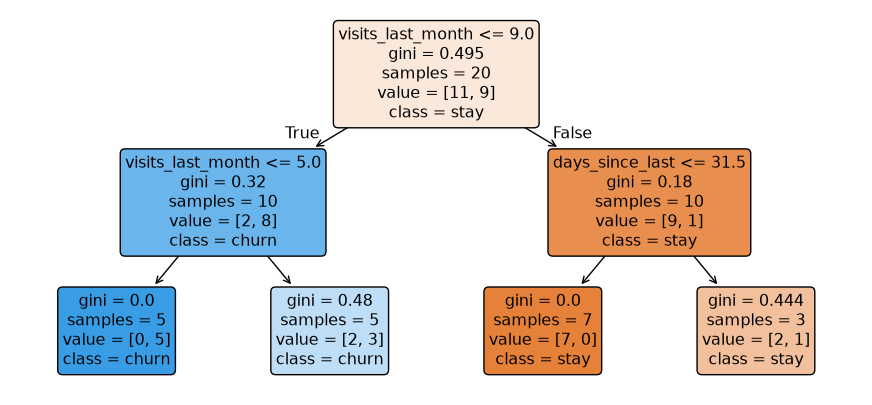

In [7]:
plt.figure(figsize=(11, 5))
plot_tree(tree, feature_names=list(X20.columns), class_names=["stay", "churn"], filled=True, rounded=True)
plt.show()

Read each box: the question, its Gini, how many rows reached it, and `value = [stayed, churned]`. The root shows `gini = 0.495`, the left child `0.32`, the right `0.18`, and the leaves `[0, 5]`, `[2, 3]`, `[7, 0]`, `[2, 1]`, exactly your paper.

## 7. The real data: depth and overfitting

In [8]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


> **About `train_test_split`.** We hold back 25% of customers and score the model only on those, because scoring a model on the rows it learned from is like marking your own homework. Module 04 explains this properly; for now, just know that `X_test` / `y_test` are "exam" customers the model never saw.

In [9]:
print(f"{'max_depth':>10} {'train acc':>10} {'test acc':>10}")
for depth in [1, 2, 3, 5, None]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    print(f"{str(depth):>10} {t.score(X_train, y_train):>10.1%} {t.score(X_test, y_test):>10.1%}")

 max_depth  train acc   test acc
         1      65.8%      65.9%
         2      66.4%      64.3%
         3      68.2%      65.8%
         5      70.7%      64.9%
      None     100.0%      59.9%


The unlimited tree is perfect on the customers it saw and the worst on the ones it did not. Depth 1–3 is where this data wants to be. Module 04 turns this observation into a method.

The readable version:

In [10]:
tree2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)
print(export_text(tree2, feature_names=features))

|--- orders <= 2.50
|   |--- days_since_last <= 109.00
|   |   |--- class: 0
|   |--- days_since_last >  109.00
|   |   |--- class: 1
|--- orders >  2.50
|   |--- spend <= 764.20
|   |   |--- class: 0
|   |--- spend >  764.20
|   |   |--- class: 0



*Fewer than three orders and no order for more than 109 days → churn.* A rule the retention team can act on today.

## Quiz answers

1. 0: every row in the group has the same class. 0.5: a 50/50 mix, the most impure a two-class group can be.
2. $p = 6/8 = 0.75$; $G = 1 - 0.5625 - 0.0625 = 0.375$.
3. It tries every feature and every threshold between consecutive values, computes the weighted Gini of the two resulting groups, and keeps the split with the lowest value (largest gain).
4. The second-level splits made the leaves purer but did not flip any leaf's majority class, so the predictions were unchanged.
5. The tree memorised the training rows (overfitting). Limit `max_depth` or raise `min_samples_leaf`.

**Next:** [03.4 Logistic regression](../04-logistic-regression/)